# Ejercicio Ridge, Lasso y ElasticNet
Para este ejercicio vas a trabajar con datos de ventas de una empresa que fabrica muebles en España. Esta empresa es una Pyme que demanda conocer de antemano qué ingresos va a tener cada mes, ya que necesita pedir un anticipio a su entidad financiera de cara a poder abastecerse de materia prima al comenzar el mes. Como desconoce cuánto tiene que pedir, tira al alza y acaba pagando muchos intereses. El objetivo es reducir estos gastos.

En las bases de datos de la empresa constan todos los gastos en publicidad y ventas, para cada uno de los meses desde su fundación (hace más de 15 años).

Dado que los presupuestos de marketing se cierran al principio de cada mes, la empresa necesita un modelo predictivo que le anticipe las ventas que conseguirá a final de mes en función de los gastos que realizará en marketing.

Para ello tendrás que utilizar tanto modelos de regresión normales, como regularizados.

1. Carga los datos y realiza un pequeño análisis exploratorio. Mira a ver cómo se relaciona las ventas con el resto de variables.
2. Crea varios modelos y modifica los hiperparámetros necesarios para mejorar el performance del modelo.
3. Interpreta los resultados. Traduce a una fórmula tu mejor modelo (escribir la fórmula simplemente). ¿Cuánto cambian las ventas si aumentamos la inversión en radio un punto más? ¿Y si aumentamos la inversión en TV o periódicos?

## Import libraries 

In [104]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Exploratory Data Analysis 

In [105]:
# Lectura datos, relación variables, mapas de correlación...
ingresos = pd.read_csv("data/advertising.csv")
ingresos

,Unnamed: 0,TV,radio,newpaper,sales
0,0,230.1,37.8,6s9.2,22100.0
1,1,44.5,39.3,45.1,10400.0
2,2,17.2,45.9,69.3,9300.0
3,3,151.5,41.3,58.5,18500.0
4,4,180.8,10.8,58.4,12900.0
...,...,...,...,...,...
195,195,38.2,3.7,13.8,7600.0
196,196,94.2,4.9,8.1,9700.0
197,197,177.0,9.3,6.4,12800.0
198,198,283.6,42.0,66.2,25500.0


In [106]:
ingresos = ingresos.drop(columns=['Unnamed: 0'])
ingresos

,TV,radio,newpaper,sales
0,230.1,37.8,6s9.2,22100.0
1,44.5,39.3,45.1,10400.0
2,17.2,45.9,69.3,9300.0
3,151.5,41.3,58.5,18500.0
4,180.8,10.8,58.4,12900.0
...,...,...,...,...
195,38.2,3.7,13.8,7600.0
196,94.2,4.9,8.1,9700.0
197,177.0,9.3,6.4,12800.0
198,283.6,42.0,66.2,25500.0


In [107]:
ingresos.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   TV        200 non-null    float64
 1   radio     200 non-null    float64
 2   newpaper  200 non-null    str    
 3   sales     200 non-null    float64
dtypes: float64(3), str(1)
memory usage: 6.4 KB


In [108]:
ingresos.head()

,TV,radio,newpaper,sales
0,230.1,37.8,6s9.2,22100.0
1,44.5,39.3,45.1,10400.0
2,17.2,45.9,69.3,9300.0
3,151.5,41.3,58.5,18500.0
4,180.8,10.8,58.4,12900.0


In [109]:
# Corregir el valor mal escrito en la columna 'newpaper'

ingresos['newpaper'] = ingresos['newpaper'].replace('6s9.2', '69.2').astype(float)

In [110]:
ingresos.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   TV        200 non-null    float64
 1   radio     200 non-null    float64
 2   newpaper  200 non-null    float64
 3   sales     200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


<Axes: >

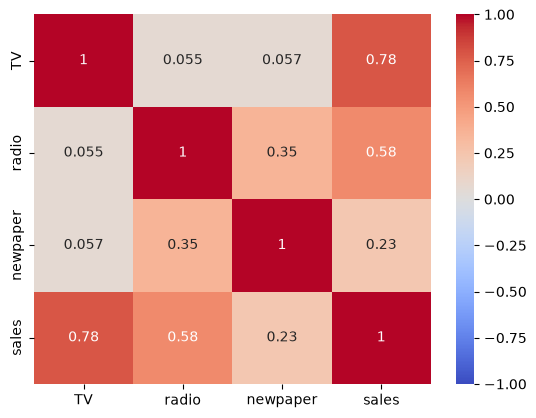

In [111]:
sns.heatmap(ingresos.corr(numeric_only=True), annot=True, cmap="coolwarm", vmin=-1)

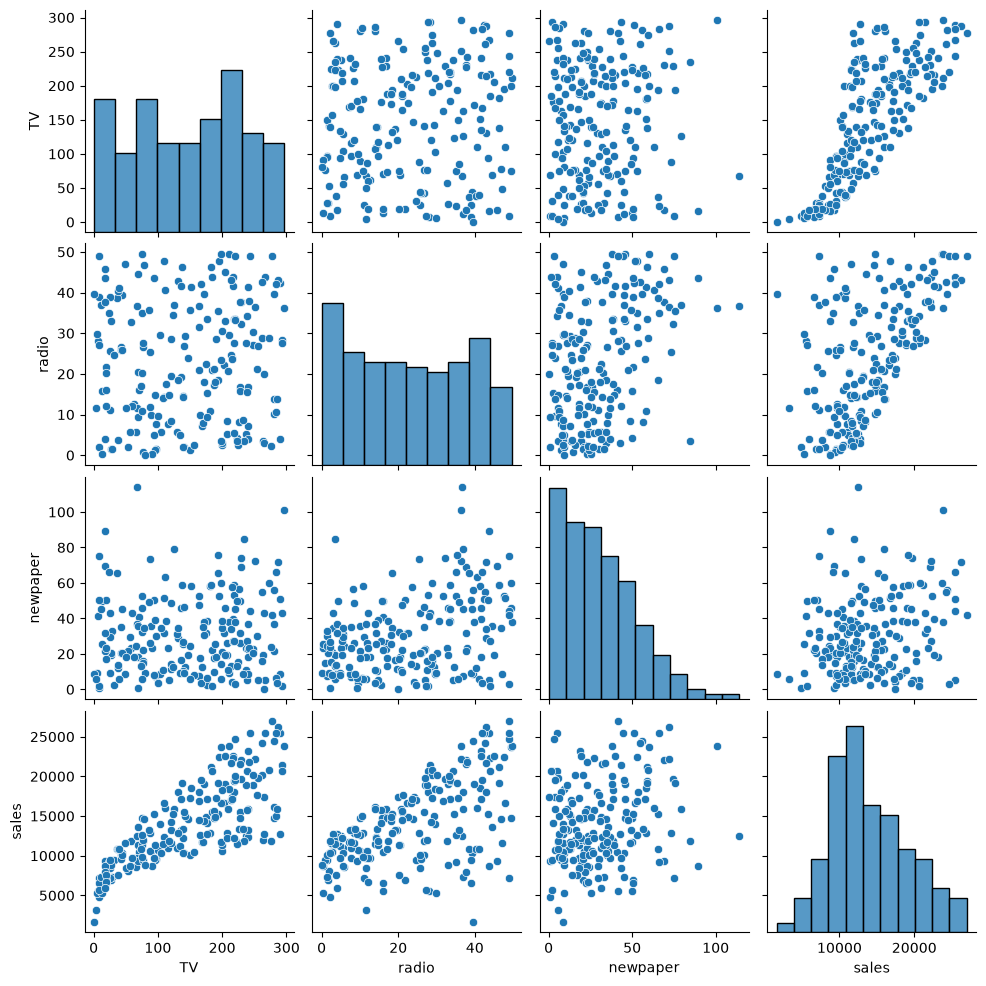

In [112]:
sns.pairplot(ingresos)

## Modelado

In [113]:
# Manipulación datasets, entrenamiento, evaluación, nuevas iteraciones... Prueba modelos sin y con regularización.

X = np.array(ingresos.drop(columns=['sales'])) # drop de y, que es el target y lo separas de X
y = np.array(ingresos['sales'])

In [114]:
X

array([[230.1,  37.8,  69.2],
       [ 44.5,  39.3,  45.1],
       [ 17.2,  45.9,  69.3],
       [151.5,  41.3,  58.5],
       [180.8,  10.8,  58.4],
       [  8.7,  48.9,  75. ],
       [ 57.5,  32.8,  23.5],
       [120.2,  19.6,  11.6],
       [  8.6,   2.1,   1. ],
       [199.8,   2.6,  21.2],
       [ 66.1,   5.8,  24.2],
       [214.7,  24. ,   4. ],
       [ 23.8,  35.1,  65.9],
       [ 97.5,   7.6,   7.2],
       [204.1,  32.9,  46. ],
       [195.4,  47.7,  52.9],
       [ 67.8,  36.6, 114. ],
       [281.4,  39.6,  55.8],
       [ 69.2,  20.5,  18.3],
       [147.3,  23.9,  19.1],
       [218.4,  27.7,  53.4],
       [237.4,   5.1,  23.5],
       [ 13.2,  15.9,  49.6],
       [228.3,  16.9,  26.2],
       [ 62.3,  12.6,  18.3],
       [262.9,   3.5,  19.5],
       [142.9,  29.3,  12.6],
       [240.1,  16.7,  22.9],
       [248.8,  27.1,  22.9],
       [ 70.6,  16. ,  40.8],
       [292.9,  28.3,  43.2],
       [112.9,  17.4,  38.6],
       [ 97.2,   1.5,  30. ],
       [26

In [115]:
y

array([22100., 10400.,  9300., 18500., 12900.,  7200., 11800., 13200.,
        4800., 10600.,  8600., 17400.,  9200.,  9700., 19000., 22400.,
       12500., 24400., 11300., 14600., 18000., 12500.,  5600., 15500.,
        9700., 12000., 15000., 15900., 18900., 10500., 21400., 11900.,
        9600., 17400.,  9500., 12800., 25400., 14700., 10100., 21500.,
       16600., 17100., 20700., 12900.,  8500., 14900., 10600., 23200.,
       14800.,  9700., 11400., 10700., 22600., 21200., 20200., 23700.,
        5500., 13200., 23800., 18400.,  8100., 24200., 15700., 14000.,
       18000.,  9300.,  9500., 13400., 18900., 22300., 18300., 12400.,
        8800., 11000., 17000.,  8700.,  6900., 14200.,  5300., 11000.,
       11800., 12300., 11300., 13600., 21700., 15200., 12000., 16000.,
       12900., 16700., 11200.,  7300., 19400., 22200., 11500., 16900.,
       11700., 15500., 25400., 17200., 11700., 23800., 14800., 14700.,
       20700., 19200.,  7200.,  8700.,  5300., 19800., 13400., 21800.,
      

In [116]:
print(X.shape)
print(y.shape)

(200, 3)
(200,)


** Hacer una regresión lieal antes de hacer el Ridge

In [117]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)


* Falta escalar

In [118]:
print("Train de datos:", X_train.shape)
print("Train de resultados:", y_train.shape)
print("Test de datos brutos:", X_test.shape)
print("Test de resultados:", y_test.shape)

Train de datos: (160, 3)
Train de resultados: (160,)
Test de datos brutos: (40, 3)
Test de resultados: (40,)


In [119]:
from sklearn.linear_model import LinearRegression

In [120]:
lm = LinearRegression()
lm.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 44.73,189.2 , 2.76]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2979
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,3
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[1064.54, 272.74, 161.52]"


In [121]:
prediccion = lm.predict(X_test)
prediccion

array([16408.02420323, 20889.88208715, 21553.84317909, 10608.50256198,
       22112.37325986, 13105.59172402, 21057.19191631,  7461.01034456,
       13606.34580543, 15155.06966892,  9048.3199241 ,  6653.28312494,
       14345.54486508,  8903.49332887,  9689.59028038, 12164.94385914,
        8736.28397336, 16265.07257725, 10277.59582057, 18831.0910344 ,
       19560.36653309, 13251.0346424 , 12336.20694824, 21306.95131746,
        7827.40305075,  5809.57447807, 20757.53231451, 11981.3807742 ,
        9183.4957628 ,  8506.69910015, 12466.46769342, 10003.37695121,
       21387.67090231, 12249.6636755 , 18266.61537608, 20137.66266542,
       14055.14005278, 20854.11186286, 11017.44410014,  4568.99622215])

In [122]:
from sklearn import metrics
print('MAE:', metrics.mean_absolute_error(y_test, prediccion))
print('MSE:', metrics.mean_squared_error(y_test, prediccion))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, prediccion)))

lm.score(X_test, y_test) #r2

MAE: 1460.7567168117598
MSE: 3174097.3539761053
RMSE: 1781.5996615334504


0.899438024100912

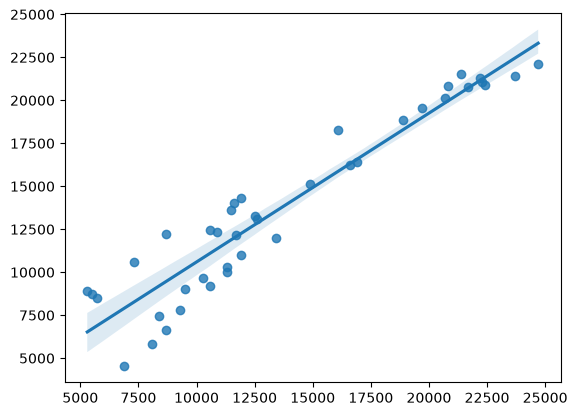

In [123]:
sns.regplot(x=y_test, y=prediccion);

### Modelos Polinómicos

In [124]:
poly_feats = PolynomialFeatures(degree = 2)
poly_feats.fit(X_train)
X_poly = poly_feats.transform(X_train)
X_poly

array([[1.00000e+00, 1.16000e+02, 7.70000e+00, ..., 5.92900e+01,
        1.77870e+02, 5.33610e+02],
       [1.00000e+00, 1.77000e+02, 9.30000e+00, ..., 8.64900e+01,
        5.95200e+01, 4.09600e+01],
       [1.00000e+00, 4.31000e+01, 2.67000e+01, ..., 7.12890e+02,
        9.37170e+02, 1.23201e+03],
       ...,
       [1.00000e+00, 2.17700e+02, 3.35000e+01, ..., 1.12225e+03,
        1.97650e+03, 3.48100e+03],
       [1.00000e+00, 1.65600e+02, 1.00000e+01, ..., 1.00000e+02,
        1.76000e+02, 3.09760e+02],
       [1.00000e+00, 2.80200e+02, 1.01000e+01, ..., 1.02010e+02,
        2.16140e+02, 4.57960e+02]], shape=(160, 10))

In [125]:
pol_reg = LinearRegression()
pol_reg.fit(X_poly, y_train)

X_test_poly = poly_feats.transform(X_test)
prediccion_poly = pol_reg.predict(X_test_poly)

In [126]:
print("MAE:", mean_absolute_error(y_test, prediccion_poly))
print("MSE:", mean_squared_error(y_test, prediccion_poly))
print("RMSE:", np.sqrt(mean_squared_error(y_test, prediccion_poly)))

pol_reg.score(X_test_poly, y_test)  # R²

MAE: 526.1794444044102
MSE: 412910.22853793425
RMSE: 642.580912055388


0.9869181490609594

<Axes: >

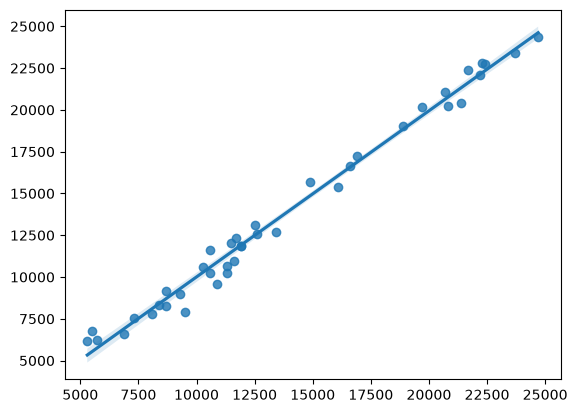

In [127]:
sns.regplot(x=y_test, y=prediccion_poly)

## Resultados

In [128]:
# buscar alpha

n_alphas = 10000
alphas = np.logspace(-4, 3, n_alphas) 

coef_ridge = [] # lista vacía
err_ridge = []
baseline = [] # error del modelo original
baseline_error = metrics.mean_squared_error(y_test, pol_reg.predict(X_test_poly))

for a in alphas: # bucle para cada uno de esos alphas
    ridge = Ridge(alpha=a) # coge un alpha
    ridge.fit(X_poly, y_train) # el fit de ese alpha
    
    coef_ridge.append(ridge.coef_) # entreno modelo
    
    y_pred = ridge.predict(X_test_poly) # predigo
    ridge_error = metrics.mean_squared_error(y_pred, y_test)
    
    err_ridge.append(ridge_error) # saco error
    baseline.append(baseline_error)

In [129]:
min(err_ridge)

409434.5427239244

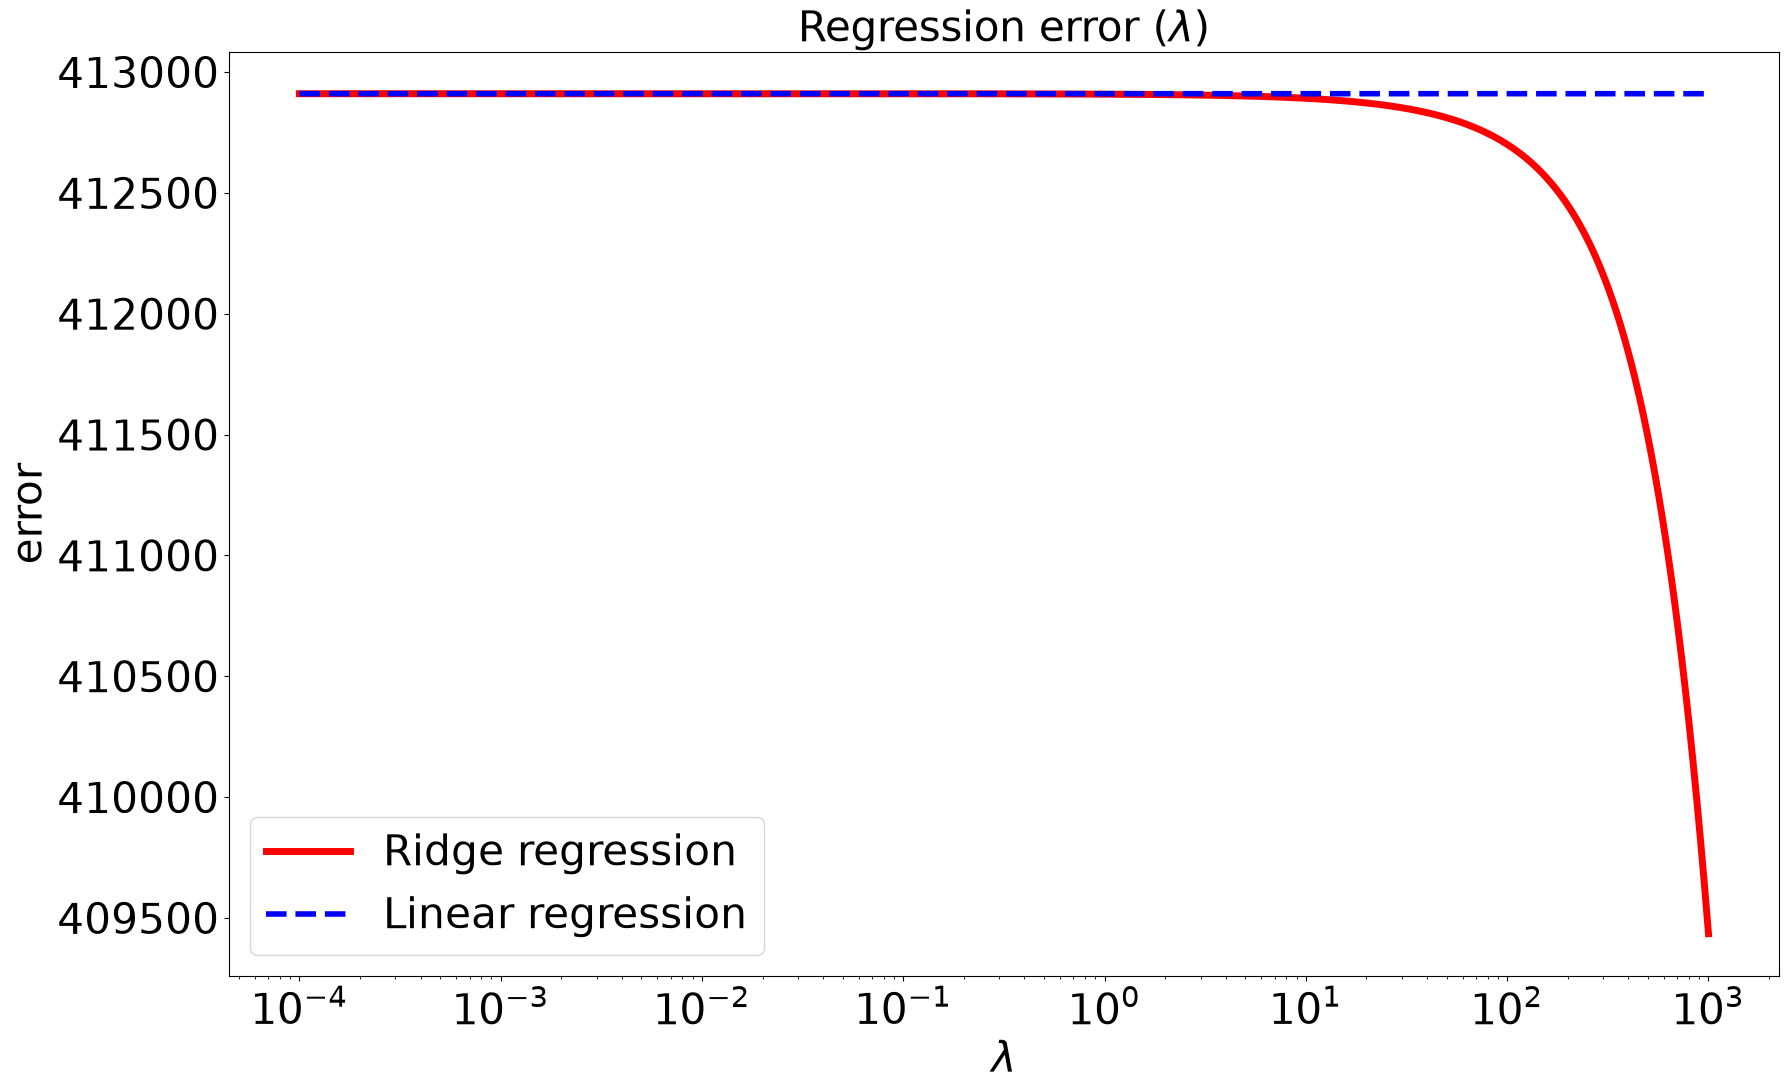

In [130]:
plt.figure(figsize=(20,12))
ax = plt.gca()
ax.plot(alphas, err_ridge, linewidth=5, color='red', label="Ridge regression")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

In [131]:
# Interpreta, resume y destaca los puntos importantes de los resultados.
from sklearn.linear_model import Ridge

ridgeR = Ridge(alpha = 1000) 
ridgeR.fit(X_poly, y_train)

print("Train MSE sin regularización:", round(metrics.mean_squared_error(y_train, pol_reg.predict(X_poly)),2)) # métricas de antes, sin ridge
print("Test MSE sin regularización:", round(metrics.mean_squared_error(y_test, pol_reg.predict(X_test_poly)),2)) # métricas de antes, sin ridge

print("Train MSE con regularización:", round(metrics.mean_squared_error(y_train, ridgeR.predict(X_poly)),2)) # nueva con ridge
print("Test MSE con regularización:", round(metrics.mean_squared_error(y_test, ridgeR.predict(X_test_poly)),2)) # nueva con ridge
# print("Test RMSE:", np.sqrt(metrics.mean_squared_error(y_test, ridgeR.predict(X_test))))

print(r2_score(y_train, ridgeR.predict(X_poly)))
print(r2_score(y_test, ridgeR.predict(X_test_poly)))



Train MSE sin regularización: 360396.67
Test MSE sin regularización: 412910.23
Train MSE con regularización: 361186.7
Test MSE con regularización: 409434.54
0.9860740584676704
0.9870282659836881


*LASSO

In [132]:
from sklearn.linear_model import Lasso

In [133]:
# Utiliza todas las celdas que necesites...
lasso = Lasso()

coef_lasso = []
err_lasso = []

for a in alphas:
    lasso.set_params(alpha=a)
    lasso.fit(X_poly, y_train)
    coef_lasso.append(lasso.coef_)
    y_pred = lasso.predict(X_test_poly)
    lasso_error = metrics.mean_squared_error(y_pred, y_test)    
    err_lasso.append(lasso_error)

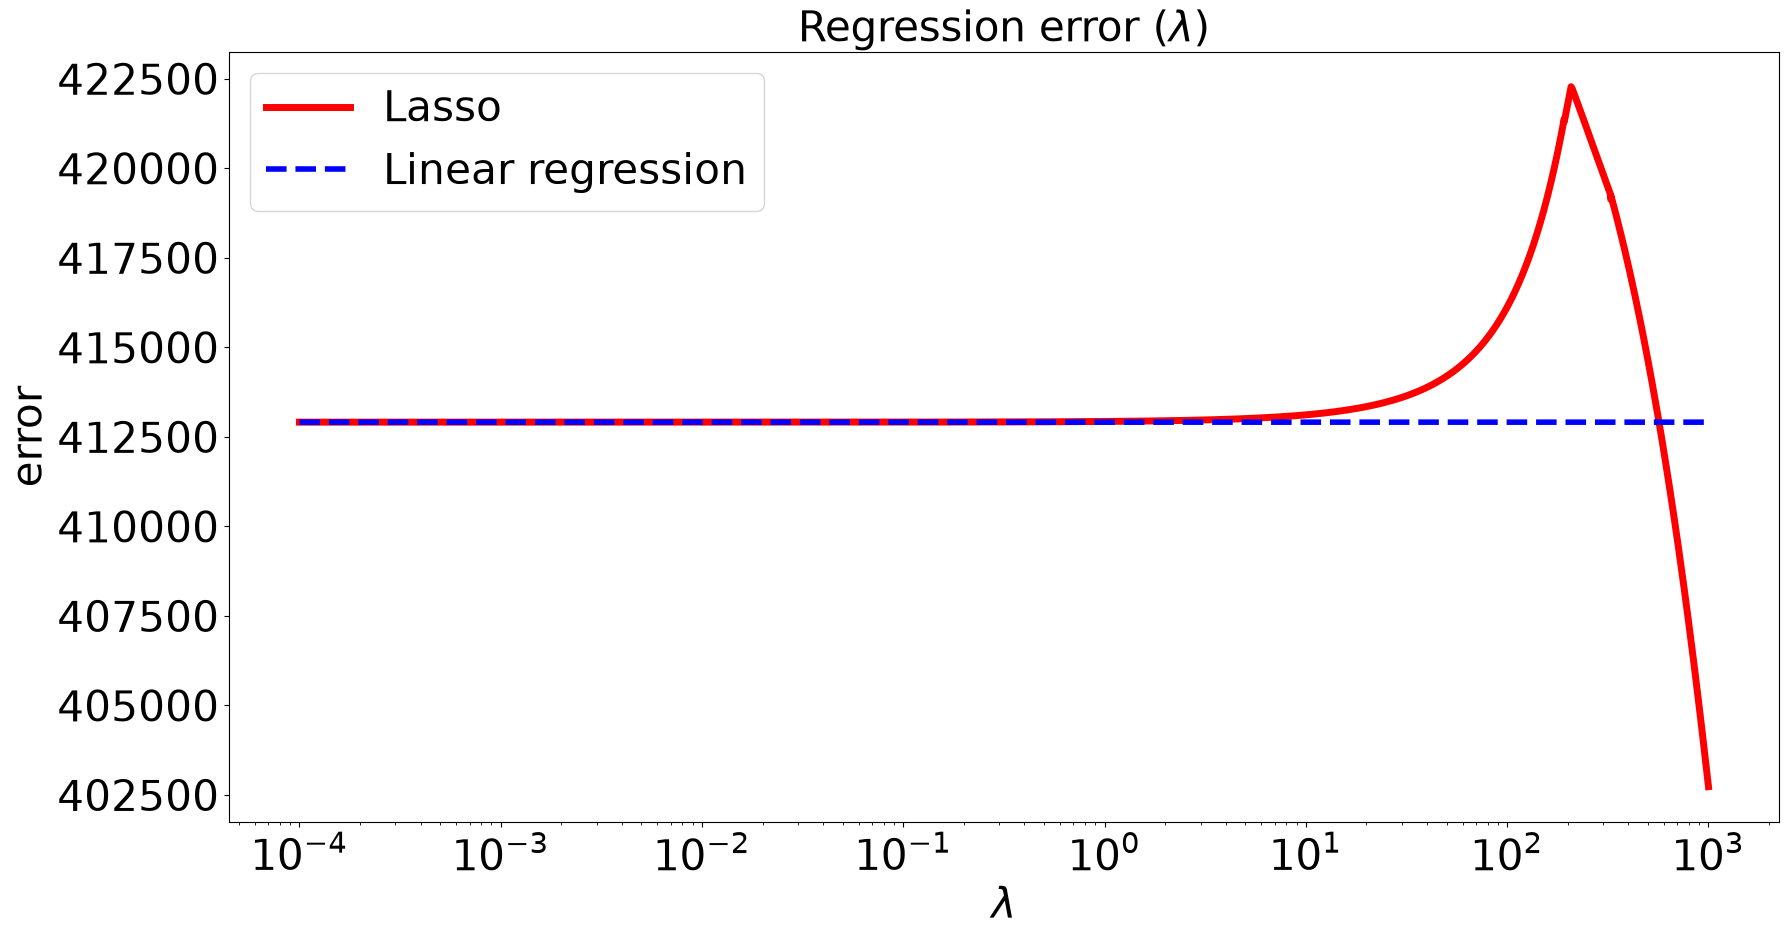

In [135]:
plt.figure(figsize=(20,10))
ax = plt.gca()
ax.plot(alphas, err_lasso, linewidth=5, color='red', label="Lasso")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

In [98]:
lassoR = Lasso(alpha=10)
lassoR.fit(X_poly, y_train)

print("Train MSE sin regularización:", round(metrics.mean_squared_error(y_train, pol_reg.predict(X_poly)),2))
print("Test MSE sin regularización:", round(metrics.mean_squared_error(y_test, pol_reg.predict(X_test_poly)),2))

print("Train MSE: %0.4f" % metrics.mean_squared_error(y_train, lassoR.predict(X_poly)))
print("Test MSE: %0.4f" % metrics.mean_squared_error(y_test, lassoR.predict(X_test_poly)))

print(r2_score(y_train, lassoR.predict(X_poly)))
print(r2_score(y_test, lassoR.predict(X_test_poly)))

Train MSE sin regularización: 360396.67
Test MSE sin regularización: 412910.23
Train MSE: 360408.1871
Test MSE: 413114.4084
0.9861040749096861
0.9869116802214308


*Elastic Net

In [99]:
from sklearn.linear_model import ElasticNet

In [100]:
coef_eln = []
err_eln = []
baseline = []
for a in alphas:
    elastic_net = ElasticNet(alpha = a, l1_ratio=0.5)
    elastic_net.fit(X_poly, y_train)
    coef_eln.append(elastic_net.coef_)
    y_pred = elastic_net.predict(X_test_poly)
    elasticnet_error = metrics.mean_squared_error(y_pred, y_test)
    err_eln.append(elasticnet_error)
    baseline.append(baseline_error)

In [101]:
min(err_eln)
# mínimo error de MSE en test

375720.5037605058

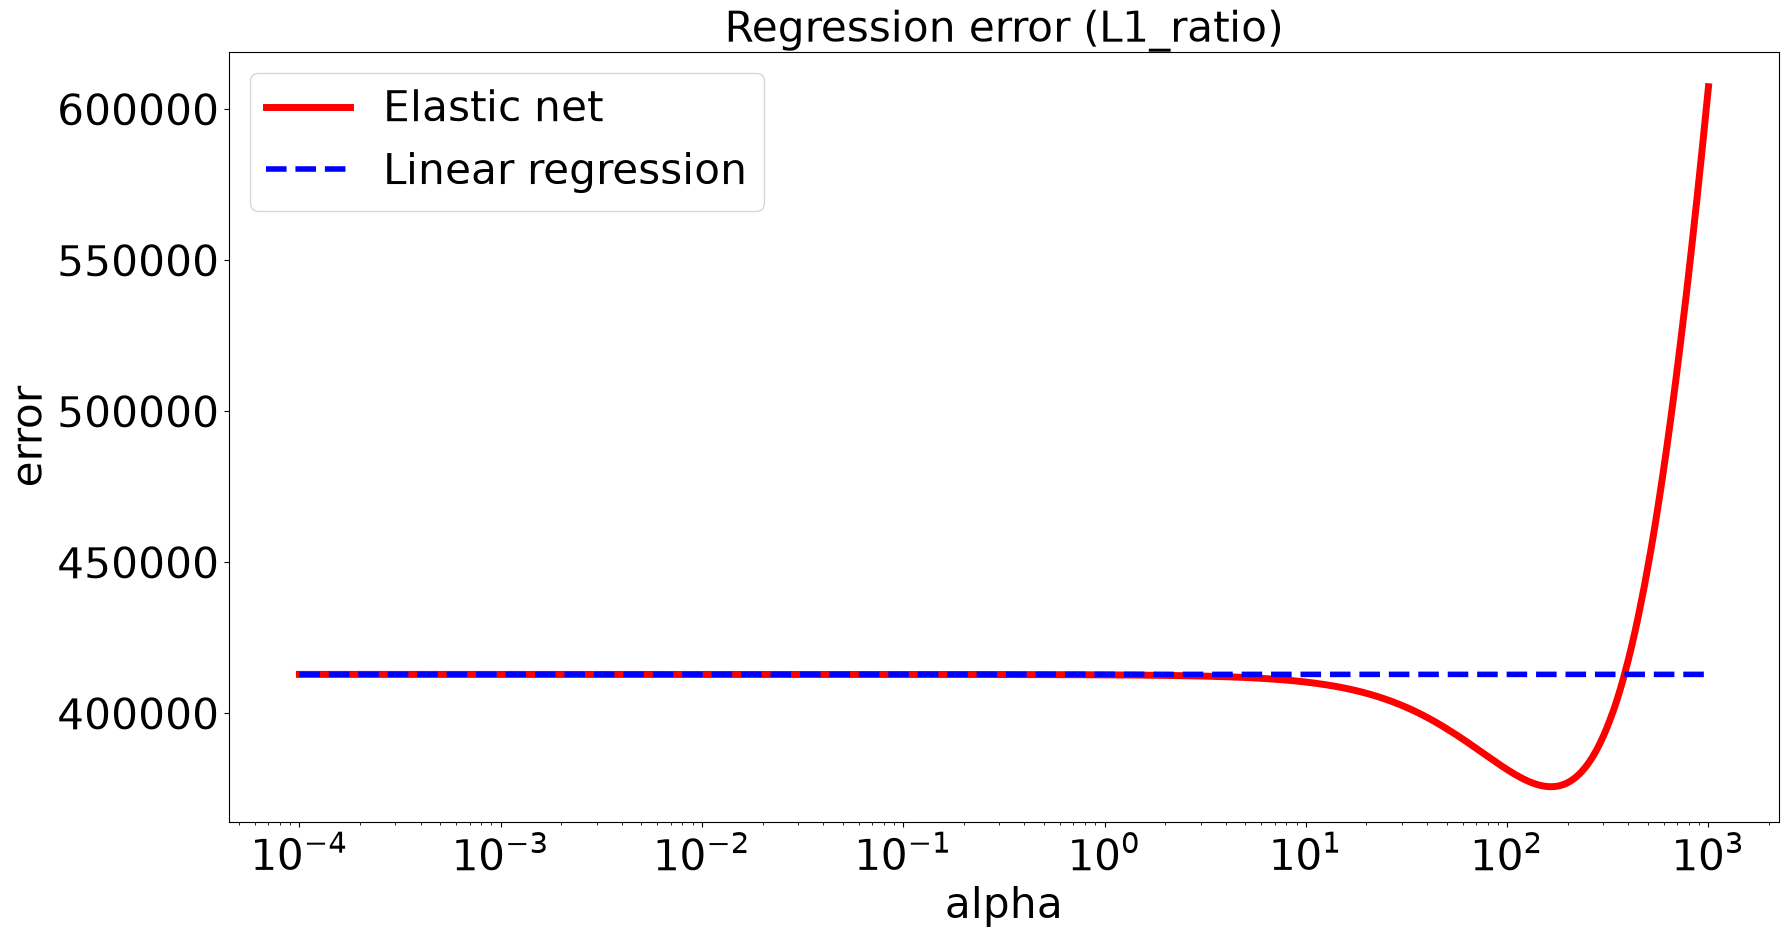

In [102]:
plt.figure(figsize=(20,10))
ax = plt.gca()
ax.plot(alphas, err_eln, linewidth=5, color='red', label="Elastic net")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel('alpha', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error (L1_ratio)', fontsize=30)
plt.show()